In [5]:
%pip install numpy pandas networkx matplotlib scipy

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.4/22.4 MB 20.7 MB/s eta 0:00:0000:0100:01

[notice] A new release of pip available: 22.2.1 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

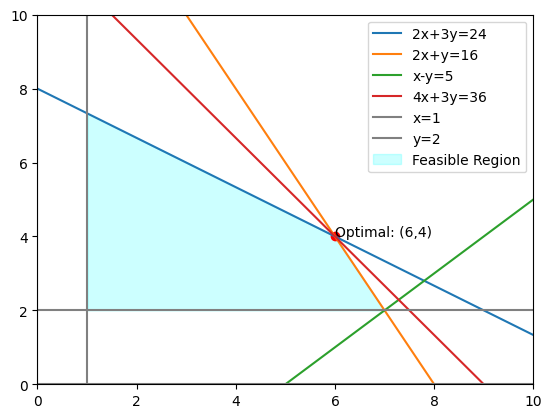

In [13]:
x = np . linspace (0 , 15 , 400)
y1 = (24 - 2* x ) / 3 # 2 x + 3 y <= 24
y2 = 16 - 2* x # 2 x + y <= 16
y3 = x - 5 # x - y <= 5
plt.plot(x,y1,label="2x+3y=24")
plt.plot(x,y2,label="2x+y=16")
plt.plot(x,y3,label="x-y=5")
plt.plot(x,(36-4*x)/3,label="4x+3y=36")
plt.axvline(0,color="gray")
plt.axhline(0,color="gray")
plt.axhline(2,color='gray',label="x=1")
plt.axvline(1,color='gray',label="y=2")

lower = np.maximum(2,y3)
upper = np.minimum(y1,y2)
# Add other lines here ...
# Fill the feasible polygon defined by the c o n s t r a i n t s
plt.fill_between(x,lower,upper,where=(x>=1)& (lower<=upper),color='aqua',alpha=0.2,label='Feasible Region')
plt.xlim((0,10));plt.ylim((0,10));plt.legend()
plt.scatter(6,4,color="red")
plt.annotate("Optimal: (6,4)",(6,4))
# plt.annotate("(1,2)",(1,2))
# plt.annotate("(1,22/3)",(1,22/3))
# plt.annotate("(7,2)",(7,2))
plt.show()

Exercise 1.2 (1)

In [10]:
c=np.array([-5,-4])
A_ub = np.array([[1,2],[3,1]])
b_ub = np.array([10,15])
A_eq = None
b_eq = None

bounds = [(0.0, None), (0.0, None)]
res = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds = bounds, method = "highs")

if not res.success:
  raise RuntimeError(res.message)

x = res.x
max_value = -res.fun
ineq_residual = b_ub - A_ub @ x
eq_residual = None

print("Optimal variables:", x)
print("Maximum values:", max_value)

Optimal variables: [4. 3.]
Maximum values: 32.0


In [15]:
c1 = np.array([2,-3,1])
A_ub1 = np.array([[-2,1,0],[0,1,0]])
b_ub1 = np.array([-5,10])
A_eq1 = np.array([[1,1,1]])
b_eq1 = np.array([20])
bounds1 = [(0,None),(0,10),(0,None)]

res1 = linprog(c1,A_ub=A_ub1,b_ub=b_ub1,A_eq=A_eq1,b_eq=b_eq1,bounds=bounds1,method = "highs")
if not res1.success:
  raise RuntimeError(res1.message)

x1 = res1.x
min_value = res1.fun
print("Optimal variables:", x1)
print("Minimum values:", min_value)

Optimal variables: [ 7.5 10.   2.5]
Minimum values: -12.5


In [16]:
c2 = np.array([-4,-1])
A_ub2 = np.array([[1,-1],[-1,-1]])
b_ub2 = np.array([8,-4])
A_eq2 = None
b_eq2 = None
bounds2 = [(0,None),(None,None)]
res2 = linprog(c2,A_ub=A_ub2,b_ub=b_ub2,A_eq=A_eq2,b_eq=b_eq2,bounds=bounds2,method = "highs")
if res2.status == 3:
  print("The problem is unbounded, so there is no finite maximum")
elif not res2.success:
  raise RuntimeError(res2.message)
else:
  x2 = res2.x
  max_value1 = -res2.fun
  print("Optimal variables:", x2)
  print("Maximum values:", max_value1)

The problem is unbounded, so there is no finite maximum


In [17]:
c3 = np.array([-20,-30,-25])
A_ub3 = np.array([[1,1,3],[1,2,1],[1,1,1]])
b_ub3 = np.array([600,500,300])
A_eq3 = None
b_eq3 = None
bounds3 = [(0,None),(0,None),(0,None)]

res3 = linprog(c3,A_ub=A_ub3,b_ub=b_ub3,A_eq=A_eq3,b_eq=b_eq3,bounds=bounds3,method = "highs")
if not res3.success:
  raise RuntimeError(res3.message)

x3 = res3.x
max_value2 = res3.fun
print("Optimal variables:", x3)
print("Maximum profits:", max_value2)

slack = res3.ineqlin.residual
shadow_prices = res3.ineqlin.marginals

operations = ["Cutting", "Assembling","Finishing"]
print(shadow_prices[0])
print(shadow_prices[1])
print(shadow_prices[2])



Optimal variables: [  0. 200. 100.]
Maximum profits: -8500.0
-0.0
-5.0
-20.0


In [57]:


availability = np.array([18,15,23,12]) #tons of imported goods
volume_per_ton = np.array([489,650,580,390])
profits_per_ton = np.array([3100,3800,3500,2850])
weight_capacity = np.array([10,16,8])
volume_capacity = np.array([6800,8700,5300])
A_ub4 = []
b_ub4 = []
c4 = -np.repeat(profits_per_ton,3)


In [58]:
for i in range(4): #available weight
    rows = np.zeros((4,3))
    rows[i,:] = 1
    A_ub4.append(rows.ravel())
    b_ub4.append(availability[i])

In [59]:
for j in range(3): #weight available
    rows = np.zeros((4,3))
    rows[:,j] = 1
    A_ub4.append(rows.ravel())
    b_ub4.append(weight_capacity[j])

In [60]:
for j in range(3): #volume capacity
    rows = np.zeros((4,3))
    rows[:,j] = volume_per_ton
    A_ub4.append(rows.ravel())
    b_ub4.append(volume_capacity[j])

In [62]:
A_eq4 = np.zeros((2,4,3)) #(equation,goods,compartment)
A_eq4[0,:,0] = 16
A_eq4[0,:,1] = -10
A_eq4[1,:,1] = 8
A_eq4[1,:,2] = -10
b_eq4 = np.zeros(2)
A_eq4 = A_eq4.reshape(2,12)


A_ub4,b_ub4 = np.array(A_ub4),np.array(b_ub4)
result = linprog(c4,A_ub = A_ub4, b_ub = b_ub4, A_eq = A_eq4, b_eq = b_eq4, bounds = (0,None), method = "highs" )

In [64]:
loading = result.x.reshape(4, 3)
print("Solver:", result.message)
print("\nOptimal loading (tons):")
print(f"{'Good':<12}{'Front':>12}{'Middle':>12}{'Rear':>12}{'Total':>12}")
for i, row in enumerate(loading, start=1):
    print(f"{i:<12}" + "".join(f"{value:12.6f}" for value in row)
          + f"{row.sum():12.6f}")
print("\nCompartment weights (t):", loading.sum(axis=0))
print("Compartment volumes (m^3):", volume_per_ton @ loading)
print(f"Maximum profit: ${-result.fun:,.2f}")
print("All availability, capacity, balance, and nonnegativity checks passed.")


Solver: Optimization terminated successfully. (HiGHS Status 7: Optimal)

Optimal loading (tons):
Good               Front      Middle        Rear       Total
1               0.000000    0.000000    0.000000    0.000000
2               6.250000    0.750000    8.000000   15.000000
3               0.000000    9.250000    0.000000    9.250000
4               0.000000    0.000000    0.000000    0.000000

Compartment weights (t): [ 6.25 10.    8.  ]
Compartment volumes (m^3): [4062.5 5852.5 5200. ]
Maximum profit: $89,375.00
All availability, capacity, balance, and nonnegativity checks passed.
